# Aşama 2 — Spark MLlib ile Illicit İşlem Tespiti

**Problem:** Bir Bitcoin işleminin illicit (fidye yazılımı, dark market, dolandırıcılık vb.) olup olmadığını özelliklerinden tahmin etmek. Bu bir **ikili sınıflandırma** problemi.

**Tasarım kararları ve gerekçeleri:**
1. **Zamansal bölme:** 1–34. adımlar eğitim, 35–49. adımlar test. Rastgele bölme, aynı zaman adımındaki ve hatta aynı işlem zincirindeki komşu işlemleri eğitim ve test kümelerine dağıtarak skoru şişirir. Bunu §6'da ölçüyoruz.
2. **Metrik:** Etiketli verinin %9.8'i illicit olduğu için accuracy yanıltıcı (hep "licit" diyen bir model %90 civarı alır). Ana metrik **illicit sınıfının F1 skoru**; destek metrikleri precision, recall ve AUC-PR.
3. **Sınıf dengesizliği:** `weightCol` ile ters frekans ağırlıklandırma. Etkisi hiperparametre olarak denenip doğrulama kümesinde seçiliyor.
4. **Sızıntısız ön işleme:** Eksik değer doldurma (Imputer) pipeline'ın parçası; yalnızca eğitim verisine fit ediliyor.

Tüm model işlemleri Spark MLlib ile yapılıyor (`pyspark.ml`); scikit-learn kullanılmıyor.

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "common").is_dir())
sys.path.insert(0, str(ROOT))
from common.spark_utils import *  # get_spark, RAW, PROC, MODELS, CHECKPOINTS, TRAIN_MAX_STEP ...
import pandas as pd
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

In [2]:
from pyspark.sql import functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import RandomForestClassifier, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
import matplotlib.pyplot as plt, json, time

spark = get_spark("02-mllib")
txs = spark.read.parquet(str(PROC / "txs"))

LOCAL = [f"Local_feature_{i}" for i in range(1, 94)]
AGG   = [f"Aggregate_feature_{i}" for i in range(1, 73)]
AUG   = ["in_txs_degree", "out_txs_degree", "size", "num_input_addresses", "num_output_addresses",
         "fee_rate_sat_b"] + sorted(c for c in txs.columns if c.startswith("log_"))
FEATURE_SETS = {"LF (93 local)": LOCAL, "AF (local+aggregate, 165)": LOCAL + AGG,
                "AF + Elliptic++ (183)": LOCAL + AGG + AUG + ["aug_missing"]}
ALL = FEATURE_SETS["AF + Elliptic++ (183)"]

labeled = txs.filter(F.col("label").isNotNull()).select("txId", "time_step", "label", *ALL).cache()
train = labeled.filter(F.col("time_step") <= TRAIN_MAX_STEP)
test  = labeled.filter(F.col("time_step") >  TRAIN_MAX_STEP)

(labeled.withColumn("küme", F.when(F.col("time_step") <= TRAIN_MAX_STEP, "eğitim (1-34)").otherwise("test (35-49)"))
        .groupBy("küme").agg(F.count("*").alias("n"), F.sum("label").cast("int").alias("illicit"))
        .withColumn("illicit %", F.round(100 * F.col("illicit") / F.col("n"), 2)).orderBy("küme").show())

:: loading settings :: url = jar:file:/usr/local/lib/python3.13/dist-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


+-------------+-----+-------+---------+
|         küme|    n|illicit|illicit %|
+-------------+-----+-------+---------+
|eğitim (1-34)|29894|   3462|    11.58|
| test (35-49)|16670|   1083|      6.5|
+-------------+-----+-------+---------+



## 1. Yardımcılar: pipeline, sınıf ağırlığı, değerlendirme

In [3]:
def class_weights(df):
    n, pos = df.count(), df.filter("label = 1").count()
    return n / (2 * pos), n / (2 * (n - pos))

def add_weight(df, w_pos, w_neg):
    return df.withColumn("w", F.when(F.col("label") == 1, w_pos).otherwise(w_neg))

def make_pipeline(features, clf, scale=False):
    aug_in = [c for c in features if c in AUG]
    stages, cols = [], []
    if aug_in:
        stages.append(Imputer(inputCols=aug_in, outputCols=[c + "_imp" for c in aug_in], strategy="median"))
    cols = [c + "_imp" if c in aug_in else c for c in features]
    stages.append(VectorAssembler(inputCols=cols, outputCol="features_raw" if scale else "features"))
    if scale:
        stages.append(StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True))
    stages.append(clf)
    return Pipeline(stages=stages)

aucpr = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="probability", metricName="areaUnderPR")

def evaluate(pred, name=""):
    c = pred.groupBy("label", "prediction").count().collect()
    m = {(r["label"], r["prediction"]): r["count"] for r in c}
    tp, fp, fn, tn = m.get((1.0, 1.0), 0), m.get((0.0, 1.0), 0), m.get((1.0, 0.0), 0), m.get((0.0, 0.0), 0)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return {"model": name, "precision": round(p, 4), "recall": round(r, 4),
            "F1 (illicit)": round(2 * p * r / (p + r), 4) if p + r else 0.0,
            "accuracy": round((tp + tn) / (tp + fp + fn + tn), 4), "AUC-PR": round(aucpr.evaluate(pred), 4),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

def rf(weighted, depth, trees=100, seed=42):
    return RandomForestClassifier(labelCol="label", featuresCol="features", numTrees=trees, maxDepth=depth,
                                  featureSubsetStrategy="sqrt", seed=seed, **({"weightCol": "w"} if weighted else {}))

## 2. Zamansal doğrulama ile hiperparametre seçimi

`CrossValidator` k katı rastgele oluşturur ve zaman sırasını bozar. Bu yüzden zamana saygılı bir doğrulama kurduk: **1–29 alt-eğitim, 30–34 doğrulama**. Test kümesine (35–49) bu aşamada hiç dokunulmuyor.

Grid: `maxDepth ∈ {8, 16}` × `sınıf ağırlığı ∈ {yok, dengeli}` (`numTrees = 100`).

In [4]:
inner = train.filter("time_step <= 29"); val = train.filter("time_step >= 30")
wp, wn = class_weights(inner)
inner_w = add_weight(inner, wp, wn).cache()
print(f"alt-eğitim: {inner.count()}  doğrulama: {val.count()}  |  w_illicit={wp:.2f}  w_licit={wn:.2f}")

grid = []
for depth in (8, 16):
    for weighted in (False, True):
        t = time.time()
        model = make_pipeline(ALL, rf(weighted, depth)).fit(inner_w)
        res = evaluate(model.transform(val), f"RF depth={depth} weighted={weighted}")
        res["fit sn"] = round(time.time() - t, 1)
        grid.append({**res, "depth": depth, "weighted": weighted})
grid_df = pd.DataFrame(grid).sort_values("F1 (illicit)", ascending=False)
grid_df[["model", "precision", "recall", "F1 (illicit)", "AUC-PR", "fit sn"]]

alt-eğitim: 26381  doğrulama: 3513  |  w_illicit=4.59  w_licit=0.56


,model,precision,recall,F1 (illicit),AUC-PR,fit sn
2,RF depth=16 weighted=False,0.9892,0.9289,0.9581,0.9870,39.7
0,RF depth=8 weighted=False,0.9890,0.9120,0.9489,0.9839,44.9
1,RF depth=8 weighted=True,0.8307,0.9712,0.8955,0.9483,25.5
3,RF depth=16 weighted=True,0.9831,0.7851,0.8730,0.9865,41.8


In [5]:
best = grid_df.iloc[0]
BEST_DEPTH, BEST_WEIGHTED = int(best["depth"]), bool(best["weighted"])
print(f"Seçilen: maxDepth={BEST_DEPTH}, weighted={BEST_WEIGHTED}")

Seçilen: maxDepth=16, weighted=False


## 3. Nihai modeller: eğitim (1–34) → test (35–49)

Seçilen Random Forest ile bir **Logistic Regression** baseline'ını karşılaştırıyoruz (StandardScaler ve ağırlıklandırmayla).

In [6]:
wp, wn = class_weights(train)
train_w = add_weight(train, wp, wn).cache()

t = time.time()
rf_model = make_pipeline(ALL, rf(BEST_WEIGHTED, BEST_DEPTH)).fit(train_w); rf_time = time.time() - t
t = time.time()
lr_model = make_pipeline(ALL, LogisticRegression(labelCol="label", featuresCol="features", weightCol="w",
                                                 maxIter=200, regParam=0.01, elasticNetParam=0.0), scale=True).fit(train_w)
lr_time = time.time() - t

rf_pred = rf_model.transform(test).cache()
lr_pred = lr_model.transform(test).cache()
results = pd.DataFrame([evaluate(rf_pred, "Random Forest"), evaluate(lr_pred, "Logistic Regression")])
results["fit sn"] = [round(rf_time, 1), round(lr_time, 1)]
results

,model,precision,recall,F1 (illicit),accuracy,AUC-PR,TP,FP,FN,TN,fit sn
0,Random Forest,0.9787,0.7211,0.8304,0.9809,0.7967,781,17,302,15570,55.0
1,Logistic Regression,0.1357,0.9372,0.2371,0.6082,0.3081,1015,6464,68,9123,16.3


## 4. Concept drift: performansın zaman adımına göre dağılımı

Test dönemi toplu olarak tek bir skora indirgendiğinde zaman içindeki yapısal kırılma görünmez. Her zaman adımı için illicit F1'i ayrı hesaplıyoruz.

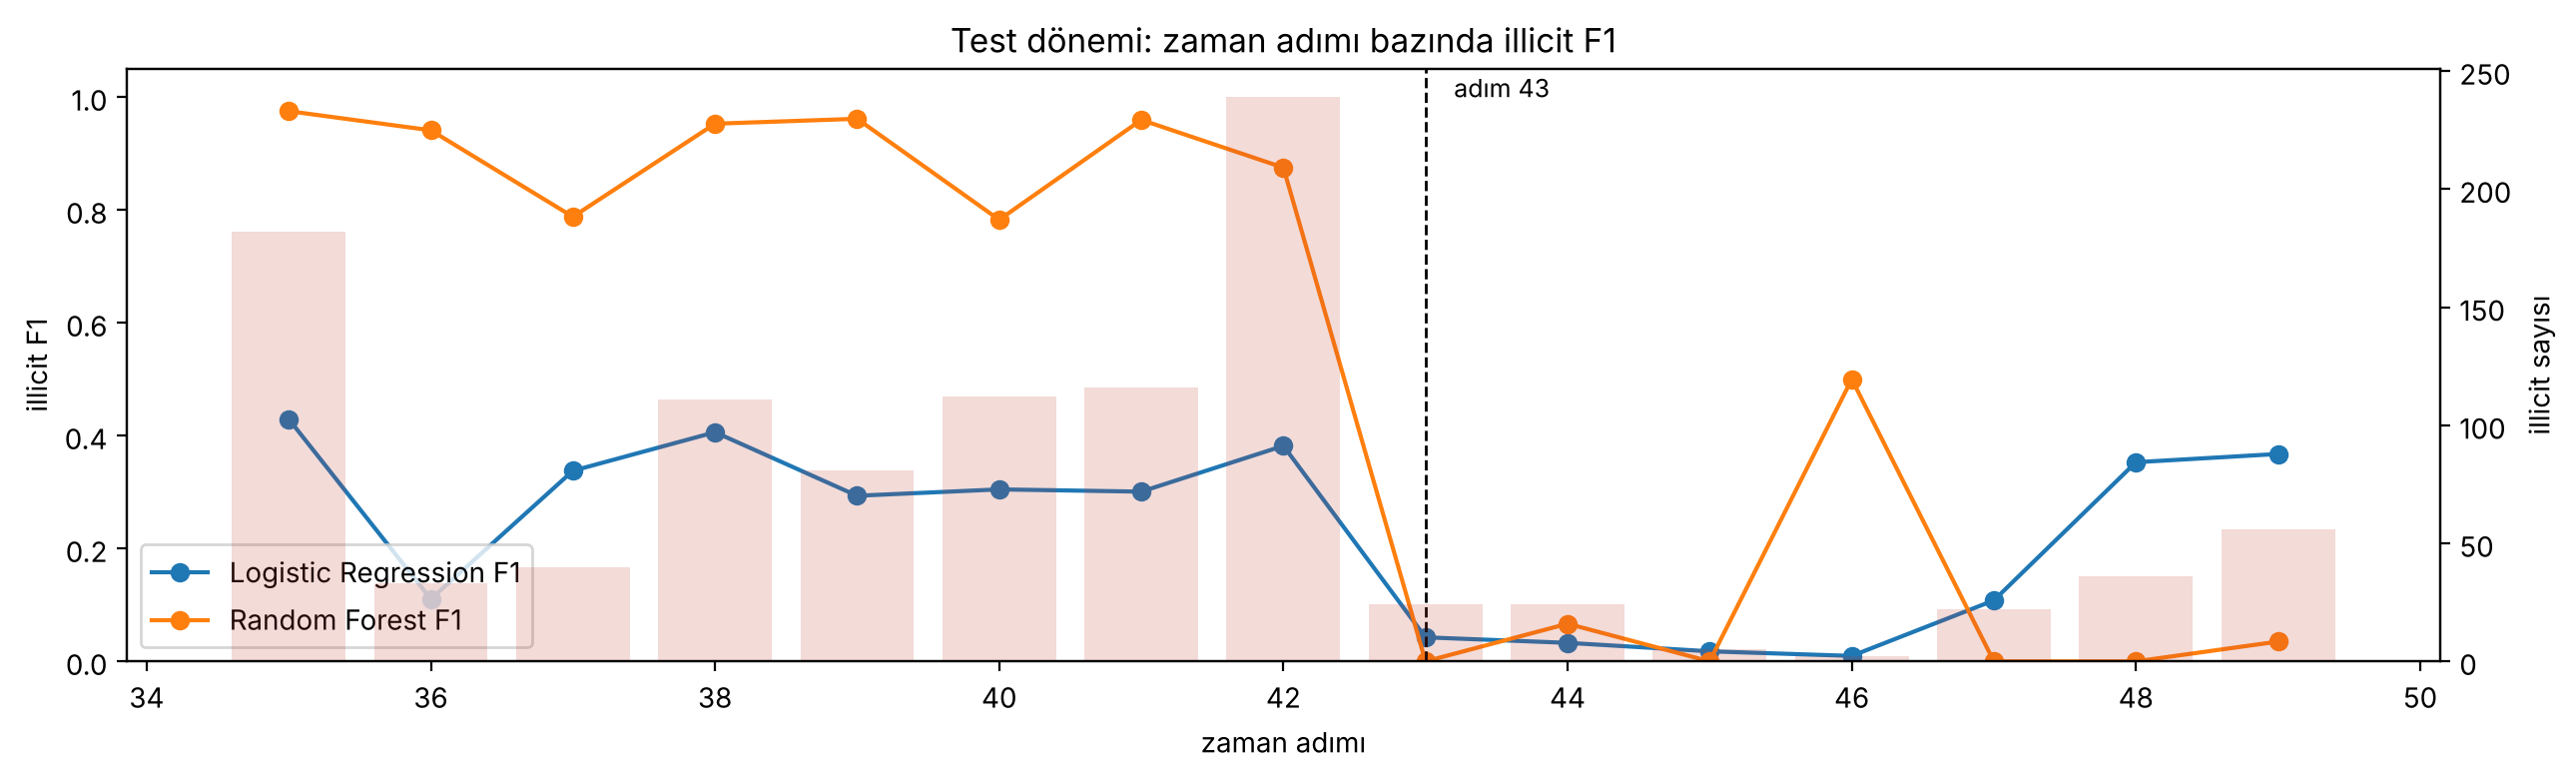

RF illicit F1  | adım 35-42: 0.9142  | adım 43-49: 0.0335


time_step,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49
illicit,182.000,33.000,40.000,111.000,81.000,112.000,116.00,239.000,24.0,24.000,5.0,2.0,22.0,36.0,56.000
tp,176.000,32.000,26.000,101.000,75.000,72.000,107.00,189.000,0.0,1.000,0.0,1.0,0.0,0.0,1.000
fp,3.000,3.000,0.000,0.000,0.000,0.000,0.00,4.000,0.0,5.000,1.0,1.0,0.0,0.0,0.000
fn,6.000,1.000,14.000,10.000,6.000,40.000,9.00,50.000,24.0,23.000,5.0,1.0,22.0,36.0,55.000
f1,0.975,0.941,0.788,0.953,0.962,0.783,0.96,0.875,0.0,0.067,0.0,0.5,0.0,0.0,0.035


In [7]:
def per_step(pred, name):
    return (pred.groupBy("time_step").agg(
                F.sum(((F.col("label") == 1) & (F.col("prediction") == 1)).cast("int")).alias("tp"),
                F.sum(((F.col("label") == 0) & (F.col("prediction") == 1)).cast("int")).alias("fp"),
                F.sum(((F.col("label") == 1) & (F.col("prediction") == 0)).cast("int")).alias("fn"),
                F.sum("label").cast("int").alias("illicit"))
            .withColumn("f1", F.when(F.col("tp") > 0, 2 * F.col("tp") / (2 * F.col("tp") + F.col("fp") + F.col("fn"))).otherwise(0.0))
            .withColumn("model", F.lit(name)).orderBy("time_step").toPandas())

ps = pd.concat([per_step(rf_pred, "Random Forest"), per_step(lr_pred, "Logistic Regression")])
fig, ax1 = plt.subplots(figsize=(13, 4))
for name, g in ps.groupby("model"):
    ax1.plot(g.time_step, g.f1, marker="o", label=f"{name} F1")
ax1.set_ylim(0, 1.05); ax1.set_xlabel("zaman adımı"); ax1.set_ylabel("illicit F1")
ax1.axvline(43, ls="--", c="k", lw=1); ax1.text(43.2, 1.0, "adım 43", fontsize=9)
ax2 = ax1.twinx(); g = ps[ps.model == "Random Forest"]
ax2.bar(g.time_step, g.illicit, alpha=.18, color="#c0392b", label="illicit sayısı"); ax2.set_ylabel("illicit sayısı")
ax1.legend(loc="lower left"); ax1.set_title("Test dönemi: zaman adımı bazında illicit F1"); plt.tight_layout(); plt.show()

pre, post = ps[(ps.model == "Random Forest") & (ps.time_step < 43)], ps[(ps.model == "Random Forest") & (ps.time_step >= 43)]
def agg_f1(d): return round(2 * d.tp.sum() / (2 * d.tp.sum() + d.fp.sum() + d.fn.sum()), 4)
print(f"RF illicit F1  | adım 35-42: {agg_f1(pre)}  | adım 43-49: {agg_f1(post)}")
ps[ps.model == "Random Forest"].set_index("time_step")[["illicit", "tp", "fp", "fn", "f1"]].round(3).T

## 5. Hangi özellikler önemli? Özellik setlerinin karşılaştırması (ablation)

Önem toplamı (grup bazında): {'Elliptic++': 0.149, 'aggregate': 0.175, 'local': 0.676}


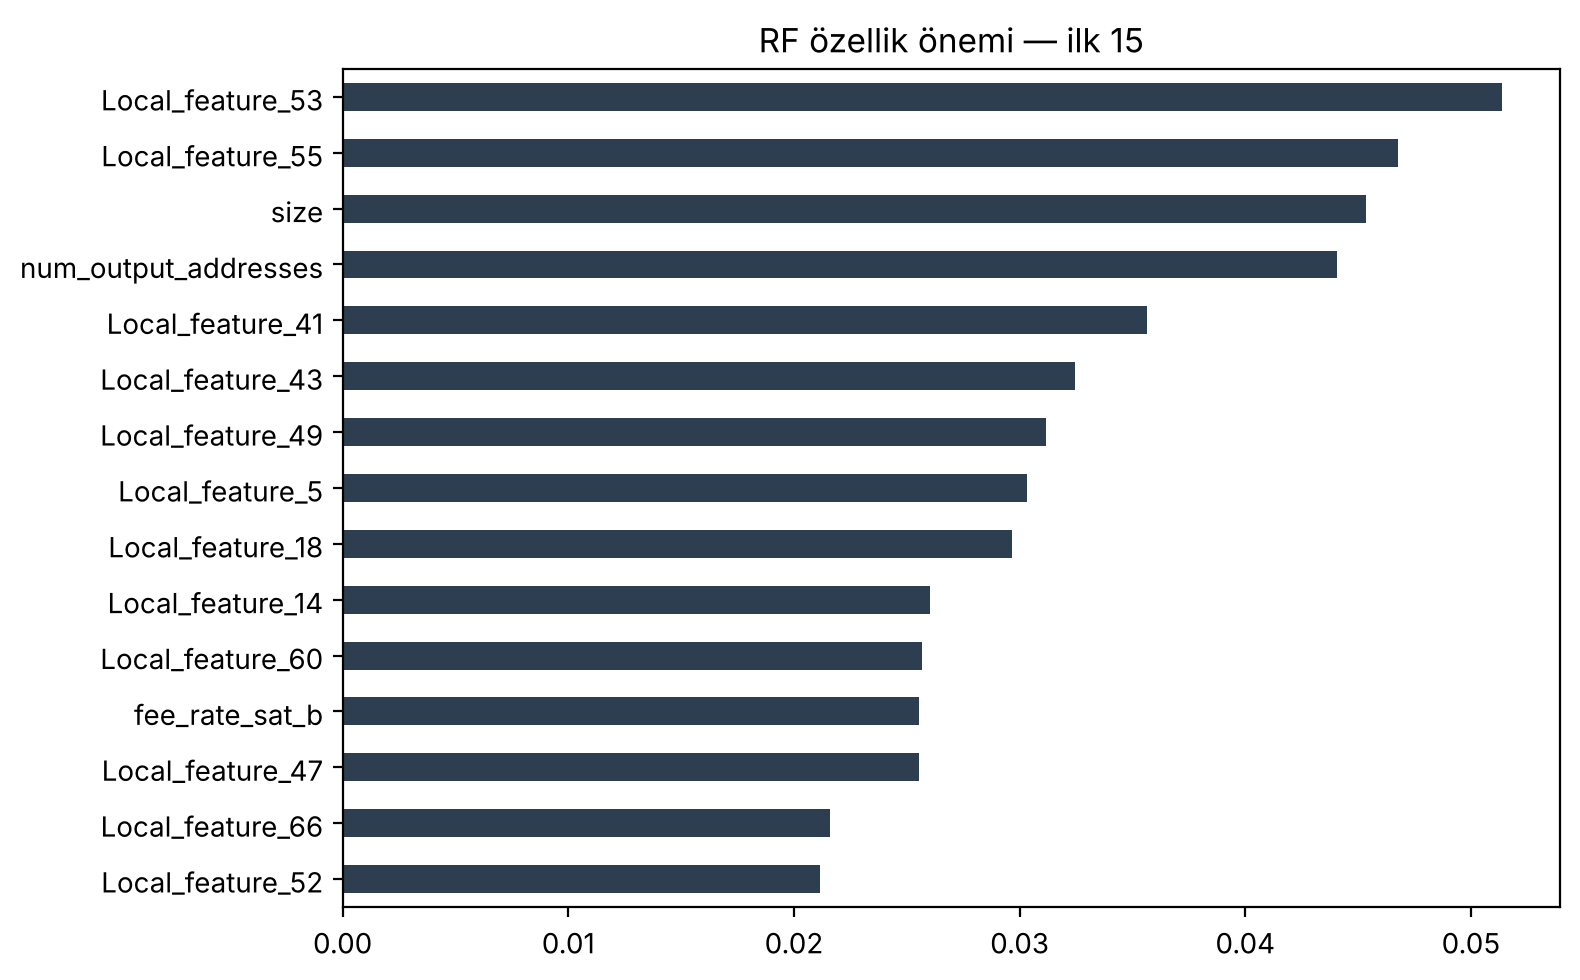

In [8]:
assembler = [s for s in rf_model.stages if isinstance(s, VectorAssembler)][0]
names = [c.removesuffix("_imp") for c in assembler.getInputCols()]
imp = pd.Series(rf_model.stages[-1].featureImportances.toArray(), index=names).sort_values(ascending=False)
group = lambda n: "local" if n.startswith("Local") else "aggregate" if n.startswith("Aggregate") else "Elliptic++"
print("Önem toplamı (grup bazında):", imp.groupby(imp.index.map(group)).sum().round(3).to_dict())
imp.head(15).iloc[::-1].plot.barh(figsize=(8, 5), color="#2c3e50", title="RF özellik önemi — ilk 15"); plt.tight_layout(); plt.show()

In [9]:
ablation = []
for name, cols in FEATURE_SETS.items():
    m = make_pipeline(cols, rf(BEST_WEIGHTED, BEST_DEPTH)).fit(train_w)
    ablation.append(evaluate(m.transform(test), name))
pd.DataFrame(ablation)[["model", "precision", "recall", "F1 (illicit)", "AUC-PR"]]

,model,precision,recall,F1 (illicit),AUC-PR
0,LF (93 local),0.8934,0.7119,0.7924,0.7819
1,"AF (local+aggregate, 165)",0.9654,0.7221,0.8262,0.7955
2,AF + Elliptic++ (183),0.9787,0.7211,0.8304,0.7967


## 6. Sızıntı deneyi: rastgele bölme neden yanıltır?

Aynı model ve aynı hiperparametrelerle **rastgele 80/20 bölme** yapıyoruz. Zamansal bölmeye göre aradaki fark, modelin gerçek dünyada göreceği performansın ne kadar fazla tahmin edileceğini gösteriyor.

In [10]:
r_train, r_test = labeled.randomSplit([0.8, 0.2], seed=7)
rwp, rwn = class_weights(r_train)
m_rand = make_pipeline(ALL, rf(BEST_WEIGHTED, BEST_DEPTH)).fit(add_weight(r_train, rwp, rwn))
leak = pd.DataFrame([evaluate(m_rand.transform(r_test), "rastgele 80/20 bölme"),
                     evaluate(rf_pred, "zamansal bölme (1-34 → 35-49)")])
leak[["model", "precision", "recall", "F1 (illicit)", "AUC-PR"]]

,model,precision,recall,F1 (illicit),AUC-PR
0,rastgele 80/20 bölme,0.9975,0.8868,0.9389,0.9790
1,zamansal bölme (1-34 → 35-49),0.9787,0.7211,0.8304,0.7967


## 7. Modeli kaydet (Aşama 3 streaming'de kullanılacak)

In [11]:
rf_model.write().overwrite().save(str(MODELS / "rf_illicit"))
meta = {"features": ALL, "threshold": 0.5, "train_steps": [1, TRAIN_MAX_STEP], "test_steps": [TRAIN_MAX_STEP + 1, 49],
        "maxDepth": BEST_DEPTH, "weighted": BEST_WEIGHTED, "numTrees": 100,
        "test_metrics": {k: v for k, v in evaluate(rf_pred, "rf").items() if k != "model"}}
(MODELS / "rf_illicit_meta.json").write_text(json.dumps(meta, indent=2))
print("kaydedildi:", MODELS / "rf_illicit"); print(json.dumps(meta["test_metrics"], indent=1))

kaydedildi: models/rf_illicit
{
 "precision": 0.9787,
 "recall": 0.7211,
 "F1 (illicit)": 0.8304,
 "accuracy": 0.9809,
 "AUC-PR": 0.7967,
 "TP": 781,
 "FP": 17,
 "FN": 302,
 "TN": 15570
}


## Sonuçların yorumu

_(Aşağıdaki sayılar bu notebook'un son çalıştırmasından alınmıştır.)_

**1. Hiperparametre seçimi (doğrulama, adım 30–34):** Sınıf ağırlıklandırma bu veride Random Forest'a **yardımcı olmadı**. Derinlik 8'de precision'ı 0.99'dan 0.83'e düşürdü, derinlik 16'da ise recall'u 0.93'ten 0.79'a çekti. Bootstrap örnekleme ve yaprak saflığı zaten azınlık sınıfını yakalayabiliyor; ağırlık karar sınırını gereğinden fazla kaydırıyor. Seçilen model: `maxDepth=16`, ağırlıksız. Bu sonucu tahmin etmek yerine ölçtük; ağırlıklandırma "dengesiz veri = her zaman ağırlık" şeklinde otomatik bir çözüm değil.

**2. Test (adım 35–49):** RF illicit **F1 = 0.830** (precision 0.979, recall 0.721, AUC-PR 0.797). Accuracy 0.981 görünüyor, ama her işleme "licit" diyen bir model de test kümesinde 0.935 alırdı (1 − 1083/16670). Accuracy'nin neden ana metrik olmadığını bu fark gösteriyor. Logistic Regression ağırlıklandırmayla recall'u 0.94'e çıkarıyor ama 6.464 yanlış alarm üretiyor (precision 0.14). Doğrusal bir karar sınırı bu problem için yetersiz.

**3. Concept drift, en önemli bulgu:** RF'nin illicit F1 skoru **35–42. adımlarda 0.914, 43–49. adımlarda 0.034**. 43. adımdan sonra model illicit işlemlerin neredeyse hiçbirini yakalayamıyor; yanlış alarm sayısı ise artmıyor. Yani model yanılmıyor, **körleşiyor**: Yeni illicit davranış, eğitim verisindeki kalıplara benzemiyor. Weber ve ark. (2019) bu kırılmayı 43. adım civarında büyük bir dark market'in kapanmasıyla açıklıyor. Pratik sonucu şu: tek seferlik eğitilen bir model bu alanda kullanılamaz. Aşama 3'teki canlı izleme (Sorgu C) tam olarak bu düşüşü yakalamak için var.

**4. Özellikler:** Önem payı local %67.6, aggregate %17.5, Elliptic++ %14.9. Ablation sonuçları: yalnızca local özelliklerle F1 0.792; aggregate (1-hop komşuluk) özellikler eklenince 0.826, ve kazancın tamamına yakını **precision'dan** geliyor (0.893 → 0.965). Elliptic++'ın eklediği 17 özellik yalnızca +0.004 getiriyor. Komşuluk bilgisi faydalı; bu, Aşama 4 ve 5'te illicit işlemlerin birbirine bağlı kümelendiğini gösteren graf analizleriyle tutarlı.

**5. Sızıntı:** Aynı model rastgele 80/20 bölmede **F1 = 0.939, AUC-PR = 0.979** alıyor. Zamansal bölmeye göre fark +0.11 F1 ve +0.18 AUC-PR. Rastgele bölme, gerçek dağıtımda karşılaşılacak performansı ciddi biçimde abartıyor; çünkü aynı zaman adımındaki kardeş işlemler hem eğitimde hem testte bulunuyor ve 43. adımdaki kırılma test kümesinde "seyreliyor".

In [12]:
spark.stop()